# Phase 8 — Frontier Context Interactions

Black-box causal benchmark over **subsets of context**, not hidden activations.

For four evidence cards, define

\[
F(S)=P(\text{correct answer}\mid \text{only evidence in }S)
\]

and compute Möbius coefficients

\[
m(T)=\sum_{U\subseteq T}(-1)^{|T|-|U|}F(U).
\]

Pilot: 12 fictional tasks, 16 subsets/task, 1 repeat, low reasoning effort.
Models: GPT-5.6 Sol, Claude Sonnet 5, Grok 4.6.
No web/tools enabled.


Set API keys before starting Jupyter:

```bash
export OPENAI_API_KEY="..."
export ANTHROPIC_API_KEY="..."
export XAI_API_KEY="..."
pip install -U openai anthropic pandas numpy matplotlib
```


In [1]:
import os, re, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI
import anthropic
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
)

C:\Users\Mauro\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
N_EVIDENCE = 4
N_TASKS = 12
N_REPEATS = 1     # after pilot, consider 3
EFFORT = "low"
BASE_SEED = 20260913
MAX_OUTPUT_TOKENS = 256

OPENAI_MODEL = "gpt-5.6-sol"
ANTHROPIC_MODEL = "claude-sonnet-5"
XAI_MODEL = "grok-4.6"

#TASK_PATH = "phase8_frontier_tasks.jsonl"
TASK_PATH = "phase8_qwen06_tasks.jsonl"
#RESULT_PATH = "phase8_frontier_raw_results.csv"
RESULT_PATH = "phase8_qwen06_raw_results.csv"

SYSTEM_PROMPT = (
    "You solve fictional evidence-integration problems. "
    "Use ONLY the evidence cards explicitly shown. "
    "If the evidence is insufficient to uniquely determine the answer, answer UNKNOWN. "
    "Return exactly one token: A, B, C, D, or UNKNOWN."
)

PROVIDERS = {
    "openai": {"model": OPENAI_MODEL, "available": bool(os.getenv("OPENAI_API_KEY"))},
    "anthropic": {"model": ANTHROPIC_MODEL, "available": bool(os.getenv("ANTHROPIC_API_KEY"))},
    "xai": {"model": XAI_MODEL, "available": bool(os.getenv("XAI_API_KEY"))},
}
display(pd.DataFrame(PROVIDERS).T)


,model,available
openai,gpt-5.6-sol,False
anthropic,claude-sonnet-5,False
xai,grok-4.6,False


In [3]:
LOCAL_MODEL_ID = "Qwen/Qwen3-0.6B"

if torch.cuda.is_available():
    LOCAL_DEVICE = "cuda"

    LOCAL_DTYPE = (
        torch.bfloat16
        if torch.cuda.is_bf16_supported()
        else torch.float16
    )

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:
    LOCAL_DEVICE = "cpu"

    # IMPORTANTE:
    # non forziamo float32.
    # Manteniamo il dtype nativo del checkpoint.
    LOCAL_DTYPE = "auto"

print("Local device:", LOCAL_DEVICE)
print("Local dtype:", LOCAL_DTYPE)

Local device: cpu
Local dtype: auto


# Troppa RAM richiesta
LOCAL_MODEL_ID = "Qwen/Qwen3-0.6B"

if torch.cuda.is_available():

    LOCAL_DEVICE = torch.device("cuda")

    if torch.cuda.is_bf16_supported():
        LOCAL_DTYPE = torch.bfloat16
    else:
        LOCAL_DTYPE = torch.float16

else:

    LOCAL_DEVICE = torch.device("cpu")
    LOCAL_DTYPE = torch.float32


print("Local device:", LOCAL_DEVICE)
print("Local dtype:", LOCAL_DTYPE)

In [4]:
# CHECK
import os

# Evita il backend Xet durante il download HF.
# Utile quando la ricostruzione di model.safetensors fallisce a metà.
os.environ["HF_HUB_DISABLE_XET"] = "1"

LOCAL_MODEL_ID = "Qwen/Qwen3-0.6B"

In [5]:
# CHECK
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

try:
    local_tokenizer = AutoTokenizer.from_pretrained(
        LOCAL_MODEL_ID,
        use_fast=True,
    )
except Exception as e:
    print("Fast tokenizer failed:", e)
    print("Falling back to slow tokenizer.")

    local_tokenizer = AutoTokenizer.from_pretrained(
        LOCAL_MODEL_ID,
        use_fast=False,
    )

# Carica il modello
local_model = AutoModelForCausalLM.from_pretrained(
    LOCAL_MODEL_ID,
    torch_dtype="auto",
    low_cpu_mem_usage=True,
)

local_model.eval()

print("loaded")
print(next(local_model.parameters()).dtype)
print(next(local_model.parameters()).device)

loaded
torch.bfloat16
cpu


In [6]:
# CHECK
import shutil
from pathlib import Path

total, used, free = shutil.disk_usage(Path.home())

print(f"Disk total: {total / 2**30:.2f} GB")
print(f"Disk free:  {free / 2**30:.2f} GB")

Disk total: 465.12 GB
Disk free:  93.06 GB


In [7]:
local_tokenizer = (
    AutoTokenizer.from_pretrained(
        LOCAL_MODEL_ID
    )
)

In [8]:
local_model = (
    AutoModelForCausalLM
    .from_pretrained(
        LOCAL_MODEL_ID,
        torch_dtype=LOCAL_DTYPE,
    )
    .to(LOCAL_DEVICE)
)

local_model.generation_config.do_sample = False
local_model.generation_config.temperature = None
local_model.generation_config.top_p = None
local_model.generation_config.top_k = None
local_model.generation_config.use_cache = True
local_model.eval()

print(
    "loaded:",
    LOCAL_MODEL_ID
)

print(
    "parameters:",
    sum(
        p.numel()
        for p in local_model.parameters()
    ) / 1e6,
    "million"
)

loaded: Qwen/Qwen3-0.6B
parameters: 596.04992 million


# Troppa RAM richiesta
local_tokenizer = (
    AutoTokenizer.from_pretrained(
        LOCAL_MODEL_ID
    )
)

local_model = (
    AutoModelForCausalLM
    .from_pretrained(
        LOCAL_MODEL_ID,
        torch_dtype=LOCAL_DTYPE,
    )
    .to(LOCAL_DEVICE)
)

local_model.eval()

print(
    "loaded:",
    LOCAL_MODEL_ID
)

print(
    "parameters:",
    sum(
        p.numel()
        for p in local_model.parameters()
    ) / 1e6,
    "million"
)

In [9]:
openai_client = OpenAI(api_key=os.environ["OPENAI_API_KEY"]) if os.getenv("OPENAI_API_KEY") else None
anthropic_client = anthropic.Anthropic(api_key=os.environ["ANTHROPIC_API_KEY"]) if os.getenv("ANTHROPIC_API_KEY") else None
xai_client = OpenAI(
    api_key=os.environ["XAI_API_KEY"],
    base_url="https://api.x.ai/v1",
) if os.getenv("XAI_API_KEY") else None

#ENABLED_PROVIDERS = [p for p,cfg in PROVIDERS.items() if cfg["available"]]
ENABLED_PROVIDERS = ["local"]
print("Enabled:", ENABLED_PROVIDERS)


Enabled: ['local']


In [10]:
def _usage(obj, name):
    u = getattr(obj, "usage", None)
    return getattr(u, name, None) if u is not None else None

def call_openai(prompt, effort=EFFORT):
    t0 = time.perf_counter()
    r = openai_client.responses.create(
        model=OPENAI_MODEL,
        reasoning={"effort": effort},
        max_output_tokens=MAX_OUTPUT_TOKENS,
        input=[
            {"role":"system","content":SYSTEM_PROMPT},
            {"role":"user","content":prompt},
        ],
    )
    return {
        "raw_text": r.output_text,
        "returned_model": getattr(r,"model",OPENAI_MODEL),
        "input_tokens": _usage(r,"input_tokens"),
        "output_tokens": _usage(r,"output_tokens"),
        "latency_sec": time.perf_counter()-t0,
        "provider_cost_usd": None,
    }

def call_anthropic(prompt, effort=EFFORT):
    t0 = time.perf_counter()
    r = anthropic_client.messages.create(
        model=ANTHROPIC_MODEL,
        max_tokens=MAX_OUTPUT_TOKENS,
        system=SYSTEM_PROMPT,
        output_config={"effort": effort},
        messages=[{"role":"user","content":prompt}],
    )
    text = "\n".join(
        b.text for b in r.content
        if getattr(b,"type",None) == "text"
    ).strip()
    return {
        "raw_text": text,
        "returned_model": getattr(r,"model",ANTHROPIC_MODEL),
        "input_tokens": getattr(r.usage,"input_tokens",None),
        "output_tokens": getattr(r.usage,"output_tokens",None),
        "latency_sec": time.perf_counter()-t0,
        "provider_cost_usd": None,
    }

def call_xai(prompt, effort=EFFORT):
    t0 = time.perf_counter()
    r = xai_client.responses.create(
        model=XAI_MODEL,
        reasoning={"effort": effort},
        max_output_tokens=MAX_OUTPUT_TOKENS,
        input=[
            {"role":"system","content":SYSTEM_PROMPT},
            {"role":"user","content":prompt},
        ],
    )
    cost = None
    u = getattr(r,"usage",None)
    ticks = getattr(u,"cost_in_usd_ticks",None) if u is not None else None
    if ticks is not None:
        cost = ticks / 1e10
    return {
        "raw_text": r.output_text,
        "returned_model": getattr(r,"model",XAI_MODEL),
        "input_tokens": _usage(r,"input_tokens"),
        "output_tokens": _usage(r,"output_tokens"),
        "latency_sec": time.perf_counter()-t0,
        "provider_cost_usd": cost,
    }
"""
def call_local(
    user_prompt,
    effort=None,
):

    t0 = time.perf_counter()

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT,
        },
        {
            "role": "user",
            "content": user_prompt,
        },
    ]

    text = (
        local_tokenizer
        .apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,

            # Importantissimo:
            # niente reasoning nascosto
            # in questo primo benchmark.
            enable_thinking=False,
        )
    )

    inputs = local_tokenizer(
        text,
        return_tensors="pt",
    ).to(
        LOCAL_DEVICE
    )

    input_len = (
        inputs["input_ids"].shape[1]
    )

    with torch.inference_mode():

        outputs = local_model.generate(
            **inputs,

            # Bastano pochi token:
            # deve produrre A/B/C/D/UNKNOWN.
            max_new_tokens=3,

            # Pilot deterministico.
            do_sample=False,

            pad_token_id=(
                local_tokenizer.eos_token_id
            ),
        )

    generated_ids = outputs[
        0,
        input_len:
    ]

    raw_text = (
        local_tokenizer.decode(
            generated_ids,
            skip_special_tokens=True,
        )
        .strip()
    )

    latency = (
        time.perf_counter()
        - t0
    )

    return {
        "raw_text":
            raw_text,

        "returned_model":
            LOCAL_MODEL_ID,

        "input_tokens":
            int(input_len),

        "output_tokens":
            int(
                generated_ids.numel()
            ),

        "latency_sec":
            latency,

        "provider_cost_usd":
            0.0,
    }
"""
def call_local(user_prompt, effort=None):
    t0 = time.perf_counter()

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt},
    ]

    try:
        text = local_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )
    except TypeError:
        text = local_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

    model_device = next(local_model.parameters()).device

    inputs = local_tokenizer(
        text,
        return_tensors="pt",
    ).to(model_device)

    input_len = inputs["input_ids"].shape[1]

    with torch.inference_mode():
        outputs = local_model.generate(
            **inputs,
            max_new_tokens=3,
            do_sample=False,
            use_cache=True,
            pad_token_id=local_tokenizer.eos_token_id,
        )

    generated_ids = outputs[0, input_len:]

    raw_text = local_tokenizer.decode(
        generated_ids,
        skip_special_tokens=True,
    ).strip()

    return {
        "raw_text": raw_text,
        "returned_model": LOCAL_MODEL_ID,
        "input_tokens": int(input_len),
        "output_tokens": int(generated_ids.numel()),
        "latency_sec": time.perf_counter() - t0,
        "provider_cost_usd": 0.0,
    }
CALLERS = {"openai":call_openai, "anthropic":call_anthropic, "xai":call_xai}


In [11]:
CALLERS["local"] = (
    call_local
)

PROVIDERS["local"] = {
    "model":
        LOCAL_MODEL_ID,

    "available":
        True,
}

In [12]:
ENABLED_PROVIDERS = [
    "local"
]

print(
    "Enabled providers:",
    ENABLED_PROVIDERS
)

Enabled providers: ['local']


In [13]:
VALID_ANSWERS = {"A","B","C","D","UNKNOWN"}

def parse_answer(text):
    if text is None:
        return None
    s = str(text).strip().upper()
    if s in VALID_ANSWERS:
        return s
    m = re.findall(r"(?<![A-Z])(UNKNOWN|A|B|C|D)(?![A-Z])", s)
    return m[-1] if m else None


## Synthetic families

- `direct`: one card sufficient.
- `redundant`: two independently sufficient cards.
- `pair_chain`: two cards jointly necessary.
- `triple_chain`: three cards jointly necessary.
- `dual_path`: two distinct 2-card sufficient paths.

This lets us verify that the measured interaction spectrum responds to known causal structure before moving to real RAG documents.


In [14]:
SYL = ["za","ke","mu","ri","to","ve","na","lo","fi","ra","su","pe","gi","xo","ba","du"]

def nonce(rng, prefix):
    return prefix+"-"+"".join(rng.choice(SYL,3))+str(rng.integers(100,999))

def mask_from_indices(indices):
    m = 0
    for i in indices:
        m |= 1 << int(i)
    return m

def permute_evidence(rng, evidence, sufficient_sets):
    perm = rng.permutation(len(evidence))
    ev = [evidence[i] for i in perm]
    old2new = {int(old):int(new) for new,old in enumerate(perm)}
    sets = [[old2new[int(i)] for i in s] for s in sufficient_sets]
    return ev, sets

def generate_task(task_id, family, rng):
    subject = nonce(rng,"subject")
    key1, key2, zone = nonce(rng,"key"), nonce(rng,"key"), nonce(rng,"zone")
    answers = [nonce(rng,"token") for _ in range(4)]
    ci = int(rng.integers(0,4))
    target = answers[ci]
    letter = "ABCD"[ci]
    o1, o2 = nonce(rng,"other"), nonce(rng,"other")
    a1, a2 = answers[(ci+1)%4], answers[(ci+2)%4]

    if family == "direct":
        ev = [
            f"The registry states that {subject} has response token {target}.",
            f"The registry states that {o1} has response token {a1}.",
            f"The archive color for {o2} is {nonce(rng,'color')}.",
            f"The unrelated code {nonce(rng,'code')} maps to {a2}.",
        ]
        suff = [{0}]
    elif family == "redundant":
        ev = [
            f"The registry states that {subject} has response token {target}.",
            f"An independent ledger also lists {target} as the response token for {subject}.",
            f"The registry states that {o1} has response token {a1}.",
            f"The registry states that {o2} has response token {a2}.",
        ]
        suff = [{0},{1}]
    elif family == "pair_chain":
        ev = [
            f"The registry assigns access code {key1} to {subject}.",
            f"Access code {key1} maps to response token {target}.",
            f"The registry assigns access code {nonce(rng,'key')} to {o1}.",
            f"Access code {nonce(rng,'key')} maps to response token {a1}.",
        ]
        suff = [{0,1}]
    elif family == "triple_chain":
        ev = [
            f"The registry assigns access code {key1} to {subject}.",
            f"Access code {key1} belongs to zone {zone}.",
            f"Zone {zone} maps to response token {target}.",
            f"The unrelated zone {nonce(rng,'zone')} maps to response token {a1}.",
        ]
        suff = [{0,1,2}]
    elif family == "dual_path":
        ev = [
            f"The registry assigns access code {key1} to {subject}.",
            f"Access code {key1} maps to response token {target}.",
            f"A second ledger assigns backup code {key2} to {subject}.",
            f"Backup code {key2} maps to response token {target}.",
        ]
        suff = [{0,1},{2,3}]
    else:
        raise ValueError(family)

    ev, suff = permute_evidence(rng, ev, suff)

    return {
        "task_id": int(task_id),
        "family": family,
        "subject": subject,
        "question": f"What is the response token for {subject}?",
        "options": dict(zip("ABCD", answers)),
        "correct_answer": letter,
        "evidence": ev,
        "minimal_sufficient_masks": [mask_from_indices(s) for s in suff],
    }

families = ["direct","redundant","pair_chain","triple_chain","dual_path"]
rng = np.random.default_rng(BASE_SEED)
tasks = [generate_task(i, families[i%len(families)], rng) for i in range(N_TASKS)]

with open(TASK_PATH,"w") as f:
    for t in tasks:
        f.write(json.dumps(t)+"\n")

pd.DataFrame([{
    "task_id":t["task_id"], "family":t["family"],
    "correct":t["correct_answer"],
    "minimal_masks":t["minimal_sufficient_masks"]
} for t in tasks])


,task_id,family,correct,minimal_masks
0,0,direct,A,[1]
1,1,redundant,C,"[4, 2]"
2,2,pair_chain,A,[3]
3,3,triple_chain,C,[11]
4,4,dual_path,A,"[3, 12]"
5,5,direct,C,[8]
6,6,redundant,B,"[4, 1]"
7,7,pair_chain,D,[3]
8,8,triple_chain,C,[13]
9,9,dual_path,C,"[12, 3]"


In [15]:
def mask_to_indices(mask):
    return [i for i in range(N_EVIDENCE) if mask & (1<<i)]

def mask_order(mask):
    return int(mask).bit_count()

def render_prompt(task, mask):
    ids = mask_to_indices(mask)
    evidence = "\n".join(
        f"[E{i+1}] {task['evidence'][i]}" for i in ids
    ) if ids else "(no evidence cards)"
    options = "\n".join(f"{k}) {v}" for k,v in task["options"].items())
    return (
        f"QUESTION\n{task['question']}\n\n"
        f"OPTIONS\n{options}\n\n"
        f"EVIDENCE CARDS\n{evidence}\n\n"
        "Return exactly one of: A, B, C, D, UNKNOWN."
    )

tasks[0]


{'task_id': 0,
 'family': 'direct',
 'subject': 'subject-murimu417',
 'question': 'What is the response token for subject-murimu417?',
 'options': {'A': 'token-bafigi387',
  'B': 'token-dupena141',
  'C': 'token-dufixo742',
  'D': 'token-narave697'},
 'correct_answer': 'A',
 'evidence': ['The registry states that subject-murimu417 has response token token-bafigi387.',
  'The archive color for other-nalofi177 is color-xobana189.',
  'The unrelated code code-tozari827 maps to token-dufixo742.',
  'The registry states that other-lovena229 has response token token-dupena141.'],
 'minimal_sufficient_masks': [1]}

## Smoke test — one call per enabled provider


In [16]:
smoke_task = tasks[0]
smoke_prompt = render_prompt(smoke_task, 15)

for provider in ENABLED_PROVIDERS:
    print("\n---", provider, "---")
    try:
        r = CALLERS[provider](smoke_prompt, EFFORT)
        print("model:", r["returned_model"])
        print("raw:", repr(r["raw_text"]))
        print("parsed:", parse_answer(r["raw_text"]))
        print("correct:", smoke_task["correct_answer"])
        print("latency:", round(r["latency_sec"],2))
    except Exception as e:
        print(type(e).__name__, str(e))



--- local ---
model: Qwen/Qwen3-0.6B
raw: 'A'
parsed: A
correct: A
latency: 228.1


In [17]:
# Sostituto
smoke_task = tasks[0]

smoke_mask = (
    (1 << N_EVIDENCE)
    - 1
)

smoke_prompt = render_prompt(
    smoke_task,
    smoke_mask
)

result = call_local(
    smoke_prompt
)

parsed = parse_answer(
    result["raw_text"]
)

print(
    "model:",
    result["returned_model"]
)

print(
    "raw:",
    repr(
        result["raw_text"]
    )
)

print(
    "parsed:",
    parsed
)

print(
    "correct:",
    smoke_task[
        "correct_answer"
    ]
)

print(
    "latency:",
    result["latency_sec"]
)

print(
    "input tokens:",
    result["input_tokens"]
)

print(
    "output tokens:",
    result["output_tokens"]
)

model: Qwen/Qwen3-0.6B
raw: 'A'
parsed: A
correct: A
latency: 223.2766658999899
input tokens: 240
output tokens: 2


In [18]:
def call_with_retry(provider, prompt, effort=EFFORT, max_attempts=5):
    err = None
    for attempt in range(max_attempts):
        try:
            return CALLERS[provider](prompt, effort)
        except Exception as e:
            err = e
            wait = min(60, 2**attempt)
            print(provider, "failed:", type(e).__name__, str(e)[:180], "| wait", wait)
            time.sleep(wait)
    raise err


In [19]:
# Check velocità
import time

prompt = render_prompt(
    tasks[0],
    15
)

t0 = time.perf_counter()

for _ in range(3):

    r = call_local(
        prompt
    )

elapsed = (
    time.perf_counter()
    - t0
)

sec_per_call = (
    elapsed / 3
)

print(
    "seconds per call:",
    sec_per_call
)

print(
    "estimated 192-call runtime:",
    sec_per_call
    * 192
    / 60,
    "minutes"
)

seconds per call: 223.25800506666806
estimated 192-call runtime: 714.4256162133378 minutes


## Resumable pilot scan

Default load: 12 tasks × 16 subsets × 1 repeat = **192 requests/provider**.
With all three providers: **576 requests**.


In [20]:
if os.path.exists(RESULT_PATH):
    results = pd.read_csv(RESULT_PATH)
else:
    results = pd.DataFrame()

done = set()

if len(results):
    done = set(zip(
        results["provider"].astype(str),
        results["task_id"].astype(int),
        results["mask"].astype(int),
        results["repeat"].astype(int),
        results["effort"].astype(str),
    ))

rows = (
    results.to_dict("records")
    if len(results)
    else []
)

TOTAL = (
    len(ENABLED_PROVIDERS)
    * len(tasks)
    * 16
    * N_REPEATS
)

print(
    "already complete:",
    len(done),
    "/",
    TOTAL,
    flush=True,
)

for provider in ENABLED_PROVIDERS:

    for task in tasks:

        for mask in range(16):

            for repeat in range(N_REPEATS):

                key = (
                    provider,
                    int(task["task_id"]),
                    int(mask),
                    int(repeat),
                    EFFORT,
                )

                if key in done:
                    continue

                print(
                    f"[{len(done)+1}/{TOTAL}] "
                    f"provider={provider} "
                    f"task={task['task_id']} "
                    f"family={task['family']} "
                    f"mask={mask:02d} "
                    f"repeat={repeat}",
                    flush=True,
                )

                prompt = render_prompt(
                    task,
                    mask,
                )

                t0 = time.perf_counter()

                try:
                    r = call_with_retry(
                        provider,
                        prompt,
                    )

                    ans = parse_answer(
                        r["raw_text"]
                    )

                    row = {
                        "provider": provider,

                        "requested_model":
                            PROVIDERS[provider]["model"],

                        "returned_model":
                            r["returned_model"],

                        "task_id":
                            task["task_id"],

                        "family":
                            task["family"],

                        "mask":
                            mask,

                        "order":
                            mask_order(mask),

                        "repeat":
                            repeat,

                        "effort":
                            EFFORT,

                        "correct_answer":
                            task["correct_answer"],

                        "parsed_answer":
                            ans,

                        "correct":
                            int(
                                ans
                                == task["correct_answer"]
                            ),

                        "raw_text":
                            r["raw_text"],

                        "input_tokens":
                            r["input_tokens"],

                        "output_tokens":
                            r["output_tokens"],

                        "latency_sec":
                            r["latency_sec"],

                        "provider_cost_usd":
                            r["provider_cost_usd"],

                        "error":
                            None,
                    }

                except Exception as e:

                    row = {
                        "provider": provider,
                        "requested_model":
                            PROVIDERS[provider]["model"],
                        "returned_model": None,
                        "task_id": task["task_id"],
                        "family": task["family"],
                        "mask": mask,
                        "order": mask_order(mask),
                        "repeat": repeat,
                        "effort": EFFORT,
                        "correct_answer":
                            task["correct_answer"],
                        "parsed_answer": None,
                        "correct": np.nan,
                        "raw_text": None,
                        "input_tokens": None,
                        "output_tokens": None,
                        "latency_sec": None,
                        "provider_cost_usd": None,
                        "error":
                            f"{type(e).__name__}: {e}",
                    }

                rows.append(row)
                done.add(key)

                # checkpoint immediato
                pd.DataFrame(rows).to_csv(
                    RESULT_PATH,
                    index=False,
                )

                elapsed = (
                    time.perf_counter()
                    - t0
                )

                print(
                    f"    -> saved "
                    f"| answer={row['parsed_answer']} "
                    f"| {elapsed:.1f}s",
                    flush=True,
                )

print("COMPLETE:", len(done), "/", TOTAL)

already complete: 38 / 192
[39/192] provider=local task=2 family=pair_chain mask=06 repeat=0
    -> saved | answer=A | 176.5s
[40/192] provider=local task=2 family=pair_chain mask=07 repeat=0
    -> saved | answer=A | 195.1s
[41/192] provider=local task=2 family=pair_chain mask=08 repeat=0
    -> saved | answer=A | 153.9s
[42/192] provider=local task=2 family=pair_chain mask=09 repeat=0
    -> saved | answer=A | 171.9s
[43/192] provider=local task=2 family=pair_chain mask=10 repeat=0
    -> saved | answer=A | 174.4s
[44/192] provider=local task=2 family=pair_chain mask=11 repeat=0
    -> saved | answer=A | 196.0s
[45/192] provider=local task=2 family=pair_chain mask=12 repeat=0
    -> saved | answer=A | 173.6s
[46/192] provider=local task=2 family=pair_chain mask=13 repeat=0
    -> saved | answer=A | 197.0s
[47/192] provider=local task=2 family=pair_chain mask=14 repeat=0
    -> saved | answer=A | 193.5s
[48/192] provider=local task=2 family=pair_chain mask=15 repeat=0
    -> saved | a

if os.path.exists(RESULT_PATH):
    results = pd.read_csv(RESULT_PATH)
else:
    results = pd.DataFrame()

done = set()
if len(results):
    done = set(zip(
        results["provider"], results["task_id"], results["mask"],
        results["repeat"], results["effort"]
    ))

rows = results.to_dict("records") if len(results) else []
print("already complete:", len(done))

for provider in ENABLED_PROVIDERS:
    for task in tasks:
        for mask in range(16):
            for repeat in range(N_REPEATS):
                key = (provider,task["task_id"],mask,repeat,EFFORT)
                if key in done:
                    continue

                prompt = render_prompt(task, mask)

                try:
                    r = call_with_retry(provider, prompt)
                    ans = parse_answer(r["raw_text"])
                    row = {
                        "provider":provider,
                        "requested_model":PROVIDERS[provider]["model"],
                        "returned_model":r["returned_model"],
                        "task_id":task["task_id"],
                        "family":task["family"],
                        "mask":mask,
                        "order":mask_order(mask),
                        "repeat":repeat,
                        "effort":EFFORT,
                        "correct_answer":task["correct_answer"],
                        "parsed_answer":ans,
                        "correct":int(ans == task["correct_answer"]),
                        "raw_text":r["raw_text"],
                        "input_tokens":r["input_tokens"],
                        "output_tokens":r["output_tokens"],
                        "latency_sec":r["latency_sec"],
                        "provider_cost_usd":r["provider_cost_usd"],
                        "error":None,
                    }
                except Exception as e:
                    row = {
                        "provider":provider, "requested_model":PROVIDERS[provider]["model"],
                        "returned_model":None, "task_id":task["task_id"],
                        "family":task["family"], "mask":mask, "order":mask_order(mask),
                        "repeat":repeat, "effort":EFFORT,
                        "correct_answer":task["correct_answer"], "parsed_answer":None,
                        "correct":np.nan, "raw_text":None, "input_tokens":None,
                        "output_tokens":None, "latency_sec":None,
                        "provider_cost_usd":None,
                        "error":f"{type(e).__name__}: {e}",
                    }

                rows.append(row)
                done.add(key)
                pd.DataFrame(rows).to_csv(RESULT_PATH,index=False)

        print(provider, "task", task["task_id"]+1, "/", len(tasks), task["family"])

results = pd.DataFrame(rows)
print("rows:", len(results), "errors:", results["error"].notna().sum())


In [21]:
audit = results.groupby("provider").agg(
    rows=("task_id","size"),
    tasks=("task_id","nunique"),
    errors=("error",lambda x:x.notna().sum()),
    parse_failures=("parsed_answer",lambda x:x.isna().sum()),
    mean_latency=("latency_sec","mean"),
    input_tokens=("input_tokens","sum"),
    output_tokens=("output_tokens","sum"),
)
display(audit)


,rows,tasks,errors,parse_failures,mean_latency,input_tokens,output_tokens
provider,,,,,,,
local,38,3,0,0,403.652596,7207,76


## Estimate \(F(S)\) and compute Möbius coefficients


In [22]:
valid = results[results["error"].isna() & results["correct"].notna()].copy()

F_df = valid.groupby(
    ["provider","task_id","family","mask"]
).agg(
    F=("correct","mean"),
    n=("correct","size")
).reset_index()

def mobius_transform(f):
    m = np.asarray(f,dtype=float).copy()
    n = int(np.log2(len(m)))
    for bit in range(n):
        step = 1<<bit
        for mask in range(len(m)):
            if mask & step:
                m[mask] -= m[mask ^ step]
    return m

def inverse_mobius(m):
    f = np.asarray(m,dtype=float).copy()
    n = int(np.log2(len(f)))
    for bit in range(n):
        step = 1<<bit
        for mask in range(len(f)):
            if mask & step:
                f[mask] += f[mask ^ step]
    return f

mobius_rows = []

for (provider,task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.sort_values("mask")
    if len(d) != 16:
        print("incomplete:", provider, task_id, len(d))
        continue
    f = d["F"].to_numpy()
    m = mobius_transform(f)
    err = np.max(np.abs(f-inverse_mobius(m)))
    family = d["family"].iloc[0]
    for mask,coef in enumerate(m):
        mobius_rows.append({
            "provider":provider,"task_id":task_id,"family":family,
            "mask":mask,"order":mask_order(mask),"mobius":coef,
            "reconstruction_error":err
        })

mobius_df = pd.DataFrame(mobius_rows)
print("max reconstruction error:", mobius_df["reconstruction_error"].max())
mobius_df.to_csv("phase8_frontier_mobius.csv",index=False)


incomplete: local 2 6
max reconstruction error: 0.0


,provider,order,mean_signed,std_signed,mean_abs,std_abs,n_tasks
0,local,0,0.5,0.707107,0.5,0.707107,2
1,local,1,0.0,0.000000,0.0,0.000000,2
2,local,2,0.0,0.000000,0.0,0.000000,2
3,local,3,0.0,0.000000,0.0,0.000000,2
4,local,4,0.0,0.000000,0.0,0.000000,2


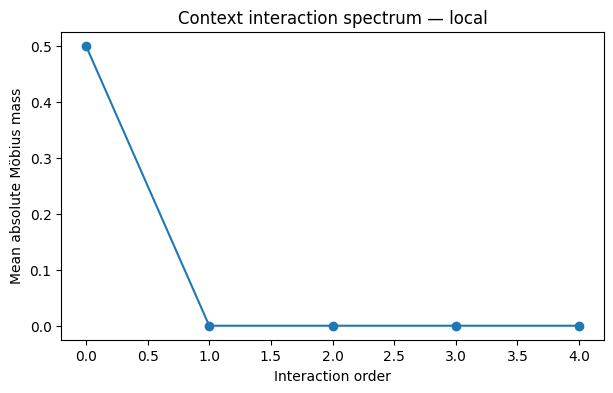

In [23]:
per_task_order = mobius_df.groupby(
    ["provider","task_id","family","order"]
).agg(
    signed_sum=("mobius","sum"),
    abs_sum=("mobius",lambda x:np.abs(x).sum())
).reset_index()

order_spectrum = per_task_order.groupby(
    ["provider","order"]
).agg(
    mean_signed=("signed_sum","mean"),
    std_signed=("signed_sum","std"),
    mean_abs=("abs_sum","mean"),
    std_abs=("abs_sum","std"),
    n_tasks=("task_id","nunique")
).reset_index()

display(order_spectrum)

for provider in sorted(order_spectrum["provider"].unique()):
    d = order_spectrum[order_spectrum["provider"]==provider]
    plt.figure(figsize=(7,4))
    plt.plot(d["order"],d["mean_abs"],marker="o")
    plt.xlabel("Interaction order")
    plt.ylabel("Mean absolute Möbius mass")
    plt.title(f"Context interaction spectrum — {provider}")
    plt.show()


## Truncation fidelity

\[
\hat F_k(S)=\sum_{T\subseteq S,\ |T|\le k}m(T)
\]

measures how many causal context orders are needed to reconstruct the response surface.


In [24]:
def truncated_reconstruction(m,k):
    z = np.asarray(m,dtype=float).copy()
    for mask in range(len(z)):
        if mask_order(mask) > k:
            z[mask] = 0
    return inverse_mobius(z)

trunc_rows = []

for (provider,task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.sort_values("mask")
    if len(d) != 16:
        continue
    f = d["F"].to_numpy()
    m = mobius_transform(f)
    family = d["family"].iloc[0]
    for k in range(1,5):
        fh = truncated_reconstruction(m,k)
        trunc_rows.append({
            "provider":provider,"task_id":task_id,"family":family,
            "max_order":k,
            "MAE":np.mean(np.abs(f-fh)),
            "max_error":np.max(np.abs(f-fh))
        })

trunc_df = pd.DataFrame(trunc_rows)
trunc_summary = trunc_df.groupby(
    ["provider","max_order"]
).agg(
    mean_MAE=("MAE","mean"),
    std_MAE=("MAE","std"),
    n_tasks=("task_id","nunique")
).reset_index()

display(trunc_summary)


,provider,max_order,mean_MAE,std_MAE,n_tasks
0,local,1,0.0,0.0,2
1,local,2,0.0,0.0,2
2,local,3,0.0,0.0,2
3,local,4,0.0,0.0,2


## Practical metric — minimal sufficient context

This is the bridge to RAG optimization: find the smallest subset of evidence that preserves a correct answer.


In [25]:
task_by_id = {t["task_id"]:t for t in tasks}
minimal_rows = []

for (provider,task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.copy()
    successful = d[d["F"] >= 0.5].copy()
    full = d[d["mask"]==15]
    full_F = full["F"].iloc[0] if len(full) else np.nan

    if len(successful):
        successful["subset_size"] = successful["mask"].map(mask_order)
        best_size = int(successful["subset_size"].min())
        best_masks = successful[
            successful["subset_size"]==best_size
        ]["mask"].astype(int).tolist()
    else:
        best_size, best_masks = None, []

    true_masks = set(task_by_id[int(task_id)]["minimal_sufficient_masks"])

    minimal_rows.append({
        "provider":provider,
        "task_id":task_id,
        "family":task_by_id[int(task_id)]["family"],
        "full_context_F":full_F,
        "minimal_empirical_size":best_size,
        "minimal_empirical_masks":best_masks,
        "ground_truth_masks":sorted(true_masks),
        "matches_ground_truth_minimal_mask":any(m in true_masks for m in best_masks),
    })

minimal_df = pd.DataFrame(minimal_rows)

practical_summary = minimal_df.groupby("provider").agg(
    full_context_accuracy=("full_context_F","mean"),
    mean_minimal_context_size=("minimal_empirical_size","mean"),
    ground_truth_selector_accuracy=("matches_ground_truth_minimal_mask","mean"),
)

display(practical_summary)


,full_context_accuracy,mean_minimal_context_size,ground_truth_selector_accuracy
provider,,,
local,0.5,0.0,0.0


In [26]:
family_spectrum = per_task_order.groupby(
    ["provider","family","order"]
).agg(
    mean_signed=("signed_sum","mean"),
    mean_abs=("abs_sum","mean"),
    n_tasks=("task_id","nunique")
).reset_index()

display(family_spectrum)

order_spectrum.to_csv("phase8_order_spectrum.csv",index=False)
trunc_summary.to_csv("phase8_truncation_summary.csv",index=False)
minimal_df.to_csv("phase8_minimal_context.csv",index=False)
family_spectrum.to_csv("phase8_family_spectrum.csv",index=False)
print("saved")


,provider,family,order,mean_signed,mean_abs,n_tasks
0,local,direct,0,1.0,1.0,1
1,local,direct,1,0.0,0.0,1
2,local,direct,2,0.0,0.0,1
3,local,direct,3,0.0,0.0,1
4,local,direct,4,0.0,0.0,1
5,local,redundant,0,0.0,0.0,1
6,local,redundant,1,0.0,0.0,1
7,local,redundant,2,0.0,0.0,1
8,local,redundant,3,0.0,0.0,1
9,local,redundant,4,0.0,0.0,1


saved


# After the pilot

Do not scale immediately.

First check that:

1. parse/error rates are near zero;
2. full-context accuracy is high;
3. `direct`, `redundant`, `pair_chain`, `triple_chain`, and `dual_path` produce qualitatively sensible spectra;
4. provider differences persist when `N_REPEATS=3`;
5. optionally repeat a small subset at `EFFORT="high"`.

Then move to **Phase 8B: real RAG context optimization**, replacing the four synthetic evidence cards with retrieved chunks and optimizing something like

\[
Utility(S)=Quality(S)-\lambda Tokens(S)-\mu Latency(S).
\]
